# fibonacci_finite_size_scaling
## 1. 研究目的
同じ初期seed pairを固定し、`1 → 10, 0 → 1` の完全なinflationだけで系サイズを増やします。
固定長の有限領域W内で連続消失と任意消失を比較し、有限サイズ依存性を調べます。

**最初の「Run All」は準備・benchmark・validationまでです。**
本計算は、設定セルの `RUN_FULL_ANALYSIS = True` に変更して再実行します。
推定時間が上限を超える場合も本計算を開始しません。

同じフォルダのPythonファイルと `reference/` が必要です。配布ZIPを展開し、このNotebookを開いてください。
実行環境: Python 3.10以上、numpy、pandas、matplotlib、Jupyter。

> **少数サンプルの実行例**
> 配布時の動作確認用です。n=4〜10、W=20,30,50、m=1,5,10、samplingは各100試行です。
> 本番用の10,000試行による結果ではありません。exactとsampledを表・図で区別しています。
> この実行例は少数サンプルなので RUN_FULL_ANALYSIS=True です。大規模な本番設定へ変更する際は、まずFalseにしてbenchmarkを確認してください。

## 2. これまでの結果と定義の継承
従来の研究では連続消失への強さが観測されました。一方、任意消失はring全体から位置を選んでいました。
今回は消失可能領域を固定するため、従来とは異なる消失配置の集合を調べます。

`fibonacci_recoverability_kl` の `recoverability_kl.py` と `legacy_functions.py` を**変更せず同梱**しています。
既存の `remaining_pattern`, `recoverability`, collision集計、`reduced_operator`、KL対角・非対角判定を使います。
論理状態は**重複を除いた**巡回軌道の正規化された等重ね合わせです。両軌道サイズが違っても、それぞれのサイズで正規化します。

再利用元とSHA256は `reference/` と `source_manifest.json` に記録しています。

## 3. finite-size scalingの考え方
固定するものはseed pair、W、m、相対消失パターンです。変えるものはinflation回数nです。
`N = len(inflate(SEED_0, n))` を自動取得し、途中でbit列を切り取りません。

windowは表示上の中央に置きますが、物理系はringです。中央配置はopen boundaryから遠ざける操作ではありません。
連続消失はwindow内の `W-m+1` 通りを全探索します。translation invarianceが成立すれば、固定pair,n,mでの連続消失率は0または1になります。

window全体がKL訂正可能なら、その全ての部分集合も訂正可能です。この包含関係も確認します。
単一サイズを無限系とは呼びません。1/N図に根拠のない外挿fitは加えません。

## 4. 手動入力セル
==============================
**ここはユーザーが手動で入力する**
==============================

--------------------------------------------------
**ここから下はユーザーが手動で設定する項目**
--------------------------------------------------

通常はこの1セルだけ変更してください。既定seedは過去の研究資料にある `L06_W03_P0001` です。
追加pairは `EXTRA_SEED_PAIRS` に辞書を追加できます。各pairは独立したlogical bitとして解析し、多次元コードを構成するものではありません。

In [1]:
# ==============================
# 手動入力する解析パラメータ
# ==============================
SEED_0 = "000111"
SEED_1 = "010101"
PAIR_ID = "L06_W03_P0001"
EXTRA_SEED_PAIRS = []  # 例: [{"pair_id": "pair_2", "seed_0": "...", "seed_1": "..."}]

INFLATION_LIST = [4, 5, 6, 7, 8, 9, 10]
WINDOW_SIZE_LIST = [20, 30, 50]
ERASURE_SIZE_LIST = [1, 5, 10]
MAX_EXACT_PATTERNS = 50
NUM_RANDOM_SAMPLES = 100
RANDOM_SEED = 42

SAVE_RESULTS = True
SAVE_FIGURES = True
OUTPUT_DIR = "example_results"

# detailは逐次保存し、画面表示用のメモリ保持はこの上限まで。
DETAIL_MODE = "all"  # all / failures / representative / none
DETAIL_MEMORY_LIMIT = 2000
DETAIL_REPRESENTATIVE_LIMIT = 100  # representative時: 全体で残す先頭の件数

BENCHMARK_PATTERNS = 100  # 各pair,nにつき100～1000。候補が少ない場合は同じ候補を繰り返し測定。
MAX_ESTIMATED_SECONDS = 600  # benchmarkを確認してから必要なら変更
RUN_FULL_ANALYSIS = True  # benchmarkとvalidationを確認後、Trueにして再実行

--------------------------------------------------
**ここから下は基本的に自動計算**
--------------------------------------------------

N、orbit、windowの位置、絶対消失位置、訂正率、理論長は自動生成します。

In [2]:
from pathlib import Path
import sys
import json
import hashlib
import warnings
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

BASE_DIR = Path.cwd().resolve()
if not (BASE_DIR / "finite_size_scaling.py").exists():
    raise FileNotFoundError("ZIPを展開し、Notebookと同じフォルダを作業ディレクトリにしてください。")
sys.path.insert(0, str(BASE_DIR))
import recoverability_kl as kl
import finite_size_scaling as fs
from theory import theory_table, paper_seed_conditions
from scaling_plots import plot_scaling, plot_heatmaps
from reporting import convergence_assessment, conclusion_markdown

CONFIG_KEYS = ["SEED_0", "SEED_1", "PAIR_ID", "EXTRA_SEED_PAIRS", "INFLATION_LIST",
    "WINDOW_SIZE_LIST", "ERASURE_SIZE_LIST", "MAX_EXACT_PATTERNS", "NUM_RANDOM_SAMPLES",
    "RANDOM_SEED", "SAVE_RESULTS", "SAVE_FIGURES", "OUTPUT_DIR", "DETAIL_MODE",
    "DETAIL_MEMORY_LIMIT", "DETAIL_REPRESENTATIVE_LIMIT", "BENCHMARK_PATTERNS",
    "MAX_ESTIMATED_SECONDS", "RUN_FULL_ANALYSIS"]
config = {key: globals()[key] for key in CONFIG_KEYS}
result = None
summary_df = pd.DataFrame()
scaling_df = pd.DataFrame()
detail_df = pd.DataFrame()
theory_comparison_df = pd.DataFrame()

## 5. 入力条件の検証
非空のbinary seed、同じk0/k1、巡回非同値、両方向の1回隣接交換条件を確認します。
位置は左から0始まり、ring境界の隣接交換も含みます。
`N < W` と `m > W` の組は警告してスキップします。Wやmが正整数でない等の設定ミスは停止します。

In [3]:
kl.verify_reference(BASE_DIR / "reference")
source_manifest = json.loads((BASE_DIR / "source_manifest.json").read_text())
for filename, expected in source_manifest["reused_files"].items():
    actual = hashlib.sha256((BASE_DIR / filename).read_bytes()).hexdigest()
    if actual != expected["sha256"]:
        raise RuntimeError(f"既存判定関数のhash不一致: {filename}")
prepared = fs.prepare(config)
print("入力検証・既存関数の同一性確認: 合格")

入力検証・既存関数の同一性確認: 合格


/Users/ideryuito/Documents/Codex/2026-10-06/files-pasted-by-the-user-fibonacci-3/outputs/fibonacci_finite_size_scaling/finite_size_scaling.py:113: RuntimeWarning: Skip L06_W03_P0001 n=4, N=39, W=50: N<W
  warnings.warn(f"Skip {p['pair_id']} n={n}, N={model.N}, W={W}: N<W", RuntimeWarning)


## 6. inflationによるNの自動生成
`prepare` はpair,nごとに `F0_n = inflate(seed_0,n)` と `F1_n = inflate(seed_1,n)` を生成し、同長性と支持の非交差を確認します。
各orbitは一度だけ生成し、W,mごとには生成し直しません。2^Nのstatevectorやdensity matrixは使用しません。

In [4]:
for (pair_id, n), model in prepared["models"].items():
    assert model.N == len(model.F0) == len(model.F1)
    assert model.F0 == kl.inflate(model.seed_0, n)
    assert model.F1 == kl.inflate(model.seed_1, n)

## 7. n–N対応表
以降の本計算より先に、実際に解析するサイズを表示します。

In [5]:
size_df = prepared["size_table"]
display(size_df)

,pair_id,seed_length,k0,k1,adjacent_swap_valid,seed_0,seed_1,inflation_n,N,orbit_size_0,orbit_size_1
0,L06_W03_P0001,6,3,3,True,000111,010101,4,39,39,13
1,L06_W03_P0001,6,3,3,True,000111,010101,5,63,63,21
2,L06_W03_P0001,6,3,3,True,000111,010101,6,102,102,34
3,L06_W03_P0001,6,3,3,True,000111,010101,7,165,165,55
4,L06_W03_P0001,6,3,3,True,000111,010101,8,267,267,89
5,L06_W03_P0001,6,3,3,True,000111,010101,9,432,432,144
6,L06_W03_P0001,6,3,3,True,000111,010101,10,699,699,233


## 8. logical pairの隣接交換条件チェック
`adjacent_swap_valid` がユーザー指定の条件です。`paper_seed_condition` は理論保証の適用に必要な条件を別途示します。
後者には自己巡回同値類へ戻る隣接交換の排除も含まれます。理論保証の追加条件によって入力を拒否することはありません。

In [6]:
seed_checks_df = pd.DataFrame([
    dict(pair, **paper_seed_conditions(pair["seed_0"], pair["seed_1"]))
    for pair in prepared["pairs"]
])
display(seed_checks_df)
assert seed_checks_df.adjacent_swap_valid.all()

,pair_id,seed_0,seed_1,seed_length,k0,k1,adjacent_swap_valid,same_composition,cyclic_inequivalent,cross_swap_01,cross_swap_10,self_swap_0,self_swap_1,paper_seed_condition
0,L06_W03_P0001,000111,010101,6,3,3,True,True,True,False,False,False,False,True


## 9. cyclic orbit生成
重複を除いたO0,O1を再利用します。周期seedでは `orbit_size < N` です。正規化をNに置き換えません。

In [7]:
orbit_df = pd.DataFrame([
    {"pair_id": pair_id, "inflation_n": n, "N": model.N,
     "orbit_size_0": len(model.O0), "orbit_size_1": len(model.O1)}
    for (pair_id, n), model in prepared["models"].items()
])
display(orbit_df)

,pair_id,inflation_n,N,orbit_size_0,orbit_size_1
0,L06_W03_P0001,4,39,39,13
1,L06_W03_P0001,5,63,63,21
2,L06_W03_P0001,6,102,102,34
3,L06_W03_P0001,7,165,165,55
4,L06_W03_P0001,8,267,267,89
5,L06_W03_P0001,9,432,432,144
6,L06_W03_P0001,10,699,699,233


## 10. window生成
`window_start=(N-W)//2`、`window_end=window_start+W-1`（終端を含む）です。
相対位置 `r` は通常 `window_start+r` に変換します。translation testではmod Nを用いて表現の切れ目をまたぐ位置も試します。

In [8]:
windows_df = prepared["windows"]
display(windows_df)

,pair_id,seed_0,seed_1,inflation_n,N,window_size,window_start,window_end,window_positions_absolute
0,L06_W03_P0001,000111,010101,4,39,20,9,28,"(9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20..."
1,L06_W03_P0001,000111,010101,4,39,30,4,33,"(4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16,..."
2,L06_W03_P0001,000111,010101,5,63,20,21,40,"(21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 3..."
3,L06_W03_P0001,000111,010101,5,63,30,16,45,"(16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 2..."
4,L06_W03_P0001,000111,010101,5,63,50,6,55,"(6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 1..."
5,L06_W03_P0001,000111,010101,6,102,20,41,60,"(41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 5..."
6,L06_W03_P0001,000111,010101,6,102,30,36,65,"(36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 4..."
7,L06_W03_P0001,000111,010101,6,102,50,26,75,"(26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 3..."
8,L06_W03_P0001,000111,010101,7,165,20,72,91,"(72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 8..."
9,L06_W03_P0001,000111,010101,7,165,30,67,96,"(67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 7..."


## 11. translation invariance test
同じ形の消失集合を複数のwindow開始位置へ移動させ、KL対角・非対角・correctabilityとrecoverabilityを照合します。
不一致時は本計算を停止します。

In [9]:
translation_df = fs.translation_test(prepared)
display(translation_df)

,pair_id,inflation_n,N,window_size,translated_start,erasure_positions_relative,erasure_positions_absolute,KL_correctable,matched
0,L06_W03_P0001,4,39,20,0,"(0,)","(0,)",True,True
1,L06_W03_P0001,4,39,20,9,"(0,)","(9,)",True,True
2,L06_W03_P0001,4,39,20,19,"(0,)","(19,)",True,True
3,L06_W03_P0001,4,39,20,38,"(0,)","(38,)",True,True
4,L06_W03_P0001,4,39,20,0,"(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...","(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...",False,True
...,...,...,...,...,...,...,...,...,...
235,L06_W03_P0001,10,699,50,698,"(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...","(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...",True,True
236,L06_W03_P0001,10,699,50,0,"(0, 25, 49)","(0, 25, 49)",True,True
237,L06_W03_P0001,10,699,50,324,"(0, 25, 49)","(324, 349, 373)",True,True
238,L06_W03_P0001,10,699,50,349,"(0, 25, 49)","(349, 374, 398)",True,True


## 12. erasure pattern生成
`C(W,m) <= MAX_EXACT_PATTERNS` なら全探索、それ以外は独立一様な復元抽出です。
同じパターンが抽出された試行も保持し、試行数として数えます。これはWilson区間の二項試行モデルと対応します。

パターン生成の乱数にはNやpairを含めません。同じW,mでは同じseedから同じ順序の相対パターン列を再生成します。
`pattern_index` とdigestで共有を確認できます。全パターンをメモリに置く必要はありません。

In [10]:
pattern_plan_df = pd.DataFrame([
    {"window_size": W, "erasure_size": m,
     "total_possible_patterns": plan.total_patterns,
     "number_of_patterns": plan.sample_count,
     "calculation_mode": "exact" if plan.mode == "exact" else "sampled",
     "contiguous_patterns": W - m + 1}
    for (W, m), plan in sorted(prepared["plans"].items())
])
display(pattern_plan_df)

,window_size,erasure_size,total_possible_patterns,number_of_patterns,calculation_mode,contiguous_patterns
0,20,1,20,20,exact,20
1,20,5,15504,100,sampled,16
2,20,10,184756,100,sampled,11
3,30,1,30,30,exact,30
4,30,5,142506,100,sampled,26
5,30,10,30045015,100,sampled,21
6,50,1,50,50,exact,50
7,50,5,2118760,100,sampled,46
8,50,10,10272278170,100,sampled,41


## 13. benchmark
各pair,nで100～1000試行を上限に評価し、orbitサイズ、実測時間、1パターンの平均時間、10,000パターンの推定時間を表示します。
W,mごとの重さが違うため複数の組を測ります。推定値は計算本体の目安であり、保存・表示等の時間も必要です。

推定時間が上限を超えた場合は自動で本計算しません。サンプル数・inflation回数・W,mを減らすか、見積りを確認して時間上限を変更してください。

In [11]:
benchmark_df = fs.benchmark(prepared, config)
display(benchmark_df)
if not benchmark_df.empty:
    estimated_seconds = float(benchmark_df.estimated_full_seconds.sum())
    print(f"本計算の推定合計: {estimated_seconds:,.1f}秒 ({estimated_seconds / 60:.1f}分)")
    display(benchmark_df.groupby(["pair_id", "inflation_n", "N", "orbit_size_0", "orbit_size_1"], as_index=False).agg(patterns=("num_benchmark_patterns", "sum"), seconds=("elapsed_seconds", "sum"), estimated_full_seconds=("estimated_full_seconds", "sum")))

本計算の推定合計: 2.6秒 (0.0分)


,pair_id,inflation_n,N,window_size,erasure_size,orbit_size_0,orbit_size_1,num_benchmark_patterns,elapsed_seconds,seconds_per_pattern,timing_source,planned_arbitrary_patterns,planned_contiguous_patterns,calculation_mode,config_fingerprint,benchmark_safety_factor,estimated_seconds_per_10000,full_window_seconds,estimated_full_seconds
0,L06_W03_P0001,4,39,20,1,39,13,17,0.000544,0.000032,measured,20,20,exact,9173a4d6d5f8892c634142fce9b76afed57a2c73834c38...,1.5,0.320049,0.000071,0.001956
1,L06_W03_P0001,4,39,20,5,39,13,17,0.000740,0.000044,measured,100,16,sampled,9173a4d6d5f8892c634142fce9b76afed57a2c73834c38...,1.5,0.435221,0.000071,0.007608
2,L06_W03_P0001,4,39,20,10,39,13,17,0.000934,0.000055,measured,100,11,sampled,9173a4d6d5f8892c634142fce9b76afed57a2c73834c38...,1.5,0.549362,0.000071,0.009182
3,L06_W03_P0001,4,39,30,1,39,13,17,0.000563,0.000033,measured,30,30,exact,9173a4d6d5f8892c634142fce9b76afed57a2c73834c38...,1.5,0.331299,0.000080,0.003022
4,L06_W03_P0001,4,39,30,5,39,13,16,0.000659,0.000041,measured,100,26,sampled,9173a4d6d5f8892c634142fce9b76afed57a2c73834c38...,1.5,0.411563,0.000080,0.007818
5,L06_W03_P0001,4,39,30,10,39,13,16,0.000703,0.000044,measured,100,21,sampled,9173a4d6d5f8892c634142fce9b76afed57a2c73834c38...,1.5,0.439427,0.000080,0.008016
6,L06_W03_P0001,5,63,20,1,63,21,12,0.000590,0.000049,measured,20,20,exact,9173a4d6d5f8892c634142fce9b76afed57a2c73834c38...,1.5,0.491319,0.000078,0.002987
7,L06_W03_P0001,5,63,20,5,63,21,11,0.000616,0.000056,measured,100,16,sampled,9173a4d6d5f8892c634142fce9b76afed57a2c73834c38...,1.5,0.560000,0.000078,0.009783
8,L06_W03_P0001,5,63,20,10,63,21,11,0.000660,0.000060,measured,100,11,sampled,9173a4d6d5f8892c634142fce9b76afed57a2c73834c38...,1.5,0.600379,0.000078,0.010035
9,L06_W03_P0001,5,63,30,1,63,21,11,0.000524,0.000048,measured,30,30,exact,9173a4d6d5f8892c634142fce9b76afed57a2c73834c38...,1.5,0.476440,0.000077,0.004327


,pair_id,inflation_n,N,orbit_size_0,orbit_size_1,patterns,seconds,estimated_full_seconds
0,L06_W03_P0001,4,39,39,13,100,0.004143,0.037602
1,L06_W03_P0001,5,63,63,21,100,0.005573,0.083090
2,L06_W03_P0001,6,102,102,34,100,0.008823,0.131176
3,L06_W03_P0001,7,165,165,55,100,0.014081,0.208136
4,L06_W03_P0001,8,267,267,89,100,0.023471,0.344234
5,L06_W03_P0001,9,432,432,144,100,0.041738,0.611010
6,L06_W03_P0001,10,699,699,233,100,0.081051,1.183444


## 14. 小規模validation
小さいNで全ての消失部分集合を列挙し、既存の整数カウント版と既存Notebookから抽出した疎KL残差版を同じseed,N,Eで照合します。
statevectorは作りません。大きな手動seedでこの全探索が難しい場合は既知の小さいseed pairも使います。
境界・正規化・包含単調性は同梱の `test_finite_size_scaling.py` でも検証します。

In [12]:
validation_df = fs.validate_small(prepared)
display(validation_df)
validation_passed = True  # 不一致時はvalidate_smallが例外を発生させ、ここには到達しない。

,pair_id,seed_0,seed_1,inflation_n,N,erasure_size,erasure_positions,KL_correctable,legacy_KL_correctable,matched
0,L06_W03_P0001,000111,010101,0,6,0,(),True,True,True
1,L06_W03_P0001,000111,010101,0,6,1,"(0,)",True,True,True
2,L06_W03_P0001,000111,010101,0,6,1,"(1,)",True,True,True
3,L06_W03_P0001,000111,010101,0,6,1,"(2,)",True,True,True
4,L06_W03_P0001,000111,010101,0,6,1,"(3,)",True,True,True
...,...,...,...,...,...,...,...,...,...,...
59,L06_W03_P0001,000111,010101,0,6,5,"(0, 1, 2, 4, 5)",False,False,True
60,L06_W03_P0001,000111,010101,0,6,5,"(0, 1, 3, 4, 5)",False,False,True
61,L06_W03_P0001,000111,010101,0,6,5,"(0, 2, 3, 4, 5)",False,False,True
62,L06_W03_P0001,000111,010101,0,6,5,"(1, 2, 3, 4, 5)",False,False,True


## 15. recoverability計算
補領域への射影が各orbit内で一対一かを調べます。
`recoverable_both` は両orbitの自己collisionが0であることです。
これは補助指標であり、量子訂正可能性の代わりには使いません。

`kl.recoverability(orbit,E)` と、既存の `LogicalPair.evaluate(E)` 内のcollision集計を再利用します。
bit mask、補領域grouping、collision counting、reduced-operator countingは独立した既存関数であり、後でC実装に置き換えやすい構造です。

## 16. KL計算
消失領域Eについて
\[
\rho_E^{ij}=\operatorname{Tr}_{E^c}(|i_L\rangle\langle j_L|)
\]
とすると、`KL_diagonal` は \(\rho_E^{00}=\rho_E^{11}\)、`KL_offdiagonal` は \(\rho_E^{01}=0\) です。
両者を満たす場合だけ `KL_correctable=True` です。

補領域が同じorbit語をgroupingし、整数カウントとorbitサイズの交差積で対角条件を厳密に判定します。
正の等振幅なので、交差ブロックの消失はcross collisionが0であることと一致します。
本計算は変更していない `kl.LogicalPair.evaluate(E)` を呼び出します。

## 17. finite-size本計算
`RUN_FULL_ANALYSIS=False` の間はこのセル以降の結果表・グラフは未計算です。
Trueでもbenchmark、translation test、small validationが完了し、時間上限内に収まる必要があります。

各Wの全消失を別にKL判定し、成功する場合に部分集合で失敗しないことを確認します。
集計は全試行に対して逐次行い、detailの保存モードには依存しません。

In [13]:
if RUN_FULL_ANALYSIS:
    result = fs.run_analysis(prepared, config, benchmark_df, validation_passed=validation_passed)
    detail_df = result["detail"]
    summary_df = result["summary"]
    scaling_df = result["scaling"]
    print("本計算が完了しました。")
else:
    print("準備完了。本計算は未実行です。benchmarkを確認後、冒頭のRUN_FULL_ANALYSISをTrueにして再実行してください。")

本計算が完了しました。


## 18. detail DataFrame
1試行につき1行です。`erasure_positions_relative` と `erasure_positions_absolute` を保存します。
`detail_df` は最大 `DETAIL_MEMORY_LIMIT` 行の表示用抜粋です。`DETAIL_MODE="all"` と `SAVE_RESULTS=True` なら完全なdetailをファイルへ逐次保存します。
failures/representative/noneの場合、その保存範囲をmetadataに記録します。画面の抜粋から訂正率を再計算しないでください。

In [14]:
display(detail_df.head(20))
if result is not None:
    display(result.get("paths", {}))

,pair_id,seed_0,seed_1,inflation_n,N,window_size,window_start,window_end,erasure_type,erasure_size,erasure_positions_relative,erasure_positions_absolute,calculation_mode,pattern_id,pattern_index,random_seed,recoverable_both,KL_diagonal,KL_offdiagonal,KL_correctable,recoverable_0,recoverable_1,self_collision_count_0,self_collision_count_1,cross_collision_count,comparison_type,KL_failure_reason
0,L06_W03_P0001,000111,010101,4,39,20,9,28,contiguous,1,"(0,)","(9,)",exact,contiguous:W20:m1:i0,0,42,True,True,True,True,True,True,0,0,0,A,none
1,L06_W03_P0001,000111,010101,4,39,20,9,28,contiguous,1,"(1,)","(10,)",exact,contiguous:W20:m1:i1,1,42,True,True,True,True,True,True,0,0,0,A,none
2,L06_W03_P0001,000111,010101,4,39,20,9,28,contiguous,1,"(2,)","(11,)",exact,contiguous:W20:m1:i2,2,42,True,True,True,True,True,True,0,0,0,A,none
3,L06_W03_P0001,000111,010101,4,39,20,9,28,contiguous,1,"(3,)","(12,)",exact,contiguous:W20:m1:i3,3,42,True,True,True,True,True,True,0,0,0,A,none
4,L06_W03_P0001,000111,010101,4,39,20,9,28,contiguous,1,"(4,)","(13,)",exact,contiguous:W20:m1:i4,4,42,True,True,True,True,True,True,0,0,0,A,none
5,L06_W03_P0001,000111,010101,4,39,20,9,28,contiguous,1,"(5,)","(14,)",exact,contiguous:W20:m1:i5,5,42,True,True,True,True,True,True,0,0,0,A,none
6,L06_W03_P0001,000111,010101,4,39,20,9,28,contiguous,1,"(6,)","(15,)",exact,contiguous:W20:m1:i6,6,42,True,True,True,True,True,True,0,0,0,A,none
7,L06_W03_P0001,000111,010101,4,39,20,9,28,contiguous,1,"(7,)","(16,)",exact,contiguous:W20:m1:i7,7,42,True,True,True,True,True,True,0,0,0,A,none
8,L06_W03_P0001,000111,010101,4,39,20,9,28,contiguous,1,"(8,)","(17,)",exact,contiguous:W20:m1:i8,8,42,True,True,True,True,True,True,0,0,0,A,none
9,L06_W03_P0001,000111,010101,4,39,20,9,28,contiguous,1,"(9,)","(18,)",exact,contiguous:W20:m1:i9,9,42,True,True,True,True,True,True,0,0,0,A,none


{'summary': '/Users/ideryuito/Documents/Codex/2026-10-06/files-pasted-by-the-user-fibonacci-3/outputs/fibonacci_finite_size_scaling/example_results/finite_size_summary.csv',
 'scaling': '/Users/ideryuito/Documents/Codex/2026-10-06/files-pasted-by-the-user-fibonacci-3/outputs/fibonacci_finite_size_scaling/example_results/finite_size_scaling.csv',
 'windows': '/Users/ideryuito/Documents/Codex/2026-10-06/files-pasted-by-the-user-fibonacci-3/outputs/fibonacci_finite_size_scaling/example_results/finite_size_windows.csv',
 'thresholds': '/Users/ideryuito/Documents/Codex/2026-10-06/files-pasted-by-the-user-fibonacci-3/outputs/fibonacci_finite_size_scaling/example_results/finite_size_thresholds.csv',
 'pair_statistics': '/Users/ideryuito/Documents/Codex/2026-10-06/files-pasted-by-the-user-fibonacci-3/outputs/fibonacci_finite_size_scaling/example_results/finite_size_pair_statistics.csv',
 'detail': '/Users/ideryuito/Documents/Codex/2026-10-06/files-pasted-by-the-user-fibonacci-3/outputs/fibonac

## 19. summary / scaling DataFrame
`gap_KL = R_KL_contiguous - R_KL_arbitrary`、`arbitrary_failure_rate = 1-R_KL_arbitrary` です。
exactにはsampling誤差がありません。sampledには点ごとの95% Wilson区間を付け、全成功でも区間幅を0にはしません。
`number_of_patterns` は両種類の試行数の合計です。`num_patterns_arbitrary` と `num_patterns_contiguous` も別列に保存します。
隣接サイズ間の `Delta_R` は有限サイズの記述量です。単調な減少や無限系への収束を仮定しません。

In [15]:
display(summary_df)
display(scaling_df)

,pair_id,seed_0,seed_1,inflation_n,N,window_size,window_start,window_end,KL_correctable_window,erasure_size,calculation_mode,calculation_mode_contiguous,num_patterns_arbitrary,num_patterns_contiguous,number_of_patterns,total_possible_arbitrary_patterns,random_seed,arbitrary_pattern_digest,contiguous_pattern_digest,previous_N,previous_inflation_n,proven_by_full_window,R_rec_contiguous,R_rec_contiguous_success_count,R_rec_contiguous_ci95_low,R_rec_contiguous_ci95_high,R_KL_contiguous,R_KL_contiguous_success_count,R_KL_contiguous_ci95_low,R_KL_contiguous_ci95_high,R_KL_diagonal_contiguous,R_KL_diagonal_contiguous_success_count,R_KL_diagonal_contiguous_ci95_low,R_KL_diagonal_contiguous_ci95_high,R_KL_offdiagonal_contiguous,R_KL_offdiagonal_contiguous_success_count,R_KL_offdiagonal_contiguous_ci95_low,R_KL_offdiagonal_contiguous_ci95_high,Type_A_count_contiguous,Type_A_rate_contiguous,...,Type_B_rate_contiguous,Type_C_count_contiguous,Type_C_rate_contiguous,Type_D_count_contiguous,Type_D_rate_contiguous,R_rec_arbitrary,R_rec_arbitrary_success_count,R_rec_arbitrary_ci95_low,R_rec_arbitrary_ci95_high,R_KL_arbitrary,R_KL_arbitrary_success_count,R_KL_arbitrary_ci95_low,R_KL_arbitrary_ci95_high,R_KL_diagonal_arbitrary,R_KL_diagonal_arbitrary_success_count,R_KL_diagonal_arbitrary_ci95_low,R_KL_diagonal_arbitrary_ci95_high,R_KL_offdiagonal_arbitrary,R_KL_offdiagonal_arbitrary_success_count,R_KL_offdiagonal_arbitrary_ci95_low,R_KL_offdiagonal_arbitrary_ci95_high,Type_A_count_arbitrary,Type_A_rate_arbitrary,Type_B_count_arbitrary,Type_B_rate_arbitrary,Type_C_count_arbitrary,Type_C_rate_arbitrary,Type_D_count_arbitrary,Type_D_rate_arbitrary,gap_KL,gap_KL_ci95_low,gap_KL_ci95_high,arbitrary_failure_rate,arbitrary_failure_rate_ci95_low,arbitrary_failure_rate_ci95_high,paired_gained_count,paired_lost_count,paired_unchanged_count,paired_delta_R_KL_arbitrary,paired_delta_standard_error
0,L06_W03_P0001,000111,010101,4,39,20,9,28,False,1,exact,exact,20,20,40,20,42,a2f8483489d604fb864f85a39fc6a3489bd19f08372cdb...,a2f8483489d604fb864f85a39fc6a3489bd19f08372cdb...,NaN,NaN,False,1.0,20,1.0,1.0,1.0,20,1.0,1.0,1.0,20,1.0,1.0,1.0,20,1.0,1.0,20,1.0,...,0.0,0,0.0,0,0.0,1.00,20,1.000000,1.000000,1.00,20,1.000000e+00,1.000000,1.00,20,1.000000e+00,1.000000,1.00,20,1.000000,1.000000,20,1.00,0,0.00,0,0.0,0,0.00,0.00,0.000000,0.000000,0.00,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
1,L06_W03_P0001,000111,010101,5,63,20,21,40,False,1,exact,exact,20,20,40,20,42,a2f8483489d604fb864f85a39fc6a3489bd19f08372cdb...,a2f8483489d604fb864f85a39fc6a3489bd19f08372cdb...,39.0,4.0,False,1.0,20,1.0,1.0,1.0,20,1.0,1.0,1.0,20,1.0,1.0,1.0,20,1.0,1.0,20,1.0,...,0.0,0,0.0,0,0.0,1.00,20,1.000000,1.000000,1.00,20,1.000000e+00,1.000000,1.00,20,1.000000e+00,1.000000,1.00,20,1.000000,1.000000,20,1.00,0,0.00,0,0.0,0,0.00,0.00,0.000000,0.000000,0.00,0.000000,0.000000,0.0,0.0,20.0,0.00,0.000000
2,L06_W03_P0001,000111,010101,6,102,20,41,60,True,1,exact,exact,20,20,40,20,42,a2f8483489d604fb864f85a39fc6a3489bd19f08372cdb...,a2f8483489d604fb864f85a39fc6a3489bd19f08372cdb...,63.0,5.0,True,1.0,20,1.0,1.0,1.0,20,1.0,1.0,1.0,20,1.0,1.0,1.0,20,1.0,1.0,20,1.0,...,0.0,0,0.0,0,0.0,1.00,20,1.000000,1.000000,1.00,20,1.000000e+00,1.000000,1.00,20,1.000000e+00,1.000000,1.00,20,1.000000,1.000000,20,1.00,0,0.00,0,0.0,0,0.00,0.00,0.000000,0.000000,0.00,0.000000,0.000000,0.0,0.0,20.0,0.00,0.000000
3,L06_W03_P0001,000111,010101,7,165,20,72,91,True,1,exact,exact,20,20,40,20,42,a2f8483489d604fb864f85a39fc6a3489bd19f08372cdb...,a2f8483489d604fb864f85a39fc6a3489bd19f08372cdb...,102.0,6.0,True,1.0,20,1.0,1.0,1.0,20,1.0,1.0,1.0,20,1.0,1.0,1.0,20,1.0,1.0,20,1.0,...,0.0,0,0.0,0,0.0,1.00,20,1.000000,1.000000,1.00,20,1.000000e+00,1.000000,1.00,20,1.000000e+00,1.000000,1.00,20,1.000000,1.000000,20,1.00,0,0.00,0,0.0,0,0.00,0.00,0.000000,0.000000,0.00,0.000000,0.000000,0.0,0.0,20.0,0.00,0.000000
4,L06_W03_P0001,000111,010101,8,267,20,123,142,True,1,exact,exact,20,20,40,20,42,a2f8483489d604fb864f85a39fc6a3489bd19f08372cdb...,a2f8

,pair_id,seed_0,seed_1,inflation_n,N,window_size,window_start,window_end,KL_correctable_window,erasure_size,calculation_mode,calculation_mode_contiguous,num_patterns_arbitrary,num_patterns_contiguous,number_of_patterns,total_possible_arbitrary_patterns,random_seed,arbitrary_pattern_digest,contiguous_pattern_digest,previous_N,previous_inflation_n,proven_by_full_window,R_rec_contiguous,R_rec_contiguous_success_count,R_rec_contiguous_ci95_low,R_rec_contiguous_ci95_high,R_KL_contiguous,R_KL_contiguous_success_count,R_KL_contiguous_ci95_low,R_KL_contiguous_ci95_high,R_KL_diagonal_contiguous,R_KL_diagonal_contiguous_success_count,R_KL_diagonal_contiguous_ci95_low,R_KL_diagonal_contiguous_ci95_high,R_KL_offdiagonal_contiguous,R_KL_offdiagonal_contiguous_success_count,R_KL_offdiagonal_contiguous_ci95_low,R_KL_offdiagonal_contiguous_ci95_high,Type_A_count_contiguous,Type_A_rate_contiguous,...,R_rec_arbitrary_ci95_low,R_rec_arbitrary_ci95_high,R_KL_arbitrary,R_KL_arbitrary_success_count,R_KL_arbitrary_ci95_low,R_KL_arbitrary_ci95_high,R_KL_diagonal_arbitrary,R_KL_diagonal_arbitrary_success_count,R_KL_diagonal_arbitrary_ci95_low,R_KL_diagonal_arbitrary_ci95_high,R_KL_offdiagonal_arbitrary,R_KL_offdiagonal_arbitrary_success_count,R_KL_offdiagonal_arbitrary_ci95_low,R_KL_offdiagonal_arbitrary_ci95_high,Type_A_count_arbitrary,Type_A_rate_arbitrary,Type_B_count_arbitrary,Type_B_rate_arbitrary,Type_C_count_arbitrary,Type_C_rate_arbitrary,Type_D_count_arbitrary,Type_D_rate_arbitrary,gap_KL,gap_KL_ci95_low,gap_KL_ci95_high,arbitrary_failure_rate,arbitrary_failure_rate_ci95_low,arbitrary_failure_rate_ci95_high,paired_gained_count,paired_lost_count,paired_unchanged_count,paired_delta_R_KL_arbitrary,paired_delta_standard_error,Delta_R_KL_contiguous,signed_Delta_R_KL_contiguous,Delta_R_KL_arbitrary,signed_Delta_R_KL_arbitrary,Delta_gap_KL,signed_Delta_gap_KL,inverse_N
0,L06_W03_P0001,000111,010101,4,39,20,9,28,False,1,exact,exact,20,20,40,20,42,a2f8483489d604fb864f85a39fc6a3489bd19f08372cdb...,a2f8483489d604fb864f85a39fc6a3489bd19f08372cdb...,NaN,NaN,False,1.0,20,1.0,1.0,1.0,20,1.0,1.0,1.0,20,1.0,1.0,1.0,20,1.0,1.0,20,1.0,...,1.000000,1.000000,1.00,20,1.000000e+00,1.000000,1.00,20,1.000000e+00,1.000000,1.00,20,1.000000,1.000000,20,1.00,0,0.00,0,0.0,0,0.00,0.00,0.000000,0.000000,0.00,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.025641
1,L06_W03_P0001,000111,010101,5,63,20,21,40,False,1,exact,exact,20,20,40,20,42,a2f8483489d604fb864f85a39fc6a3489bd19f08372cdb...,a2f8483489d604fb864f85a39fc6a3489bd19f08372cdb...,39.0,4.0,False,1.0,20,1.0,1.0,1.0,20,1.0,1.0,1.0,20,1.0,1.0,1.0,20,1.0,1.0,20,1.0,...,1.000000,1.000000,1.00,20,1.000000e+00,1.000000,1.00,20,1.000000e+00,1.000000,1.00,20,1.000000,1.000000,20,1.00,0,0.00,0,0.0,0,0.00,0.00,0.000000,0.000000,0.00,0.000000,0.000000,0.0,0.0,20.0,0.00,0.000000,0.0,0.0,0.00,0.00,0.00,0.00,0.015873
2,L06_W03_P0001,000111,010101,6,102,20,41,60,True,1,exact,exact,20,20,40,20,42,a2f8483489d604fb864f85a39fc6a3489bd19f08372cdb...,a2f8483489d604fb864f85a39fc6a3489bd19f08372cdb...,63.0,5.0,True,1.0,20,1.0,1.0,1.0,20,1.0,1.0,1.0,20,1.0,1.0,1.0,20,1.0,1.0,20,1.0,...,1.000000,1.000000,1.00,20,1.000000e+00,1.000000,1.00,20,1.000000e+00,1.000000,1.00,20,1.000000,1.000000,20,1.00,0,0.00,0,0.0,0,0.00,0.00,0.000000,0.000000,0.00,0.000000,0.000000,0.0,0.0,20.0,0.00,0.000000,0.0,0.0,0.00,0.00,0.00,0.00,0.009804
3,L06_W03_P0001,000111,010101,7,165,20,72,91,True,1,exact,exact,20,20,40,20,42,a2f8483489d604fb864f85a39fc6a3489bd19f08372cdb...,a2f8483489d604fb864f85a39fc6a3489bd19f08372cdb...,102.0,6.0,True,1.0,20,1.0,1.0,1.0,20,1.0,1.0,1.0,20,1.0,1.0,1.0,20,1.0,1.0,20,1.0,...,1.000000,1.000000,1.00,20,1.000000e+00,1.000000,1.00,20,1.000000e+00,1.000000,1.00,20,1.000000,1.000000,20,1.00,0,0.00,0,0.0,0,0.00,0.00,0.000000,0.000000,0.00,0.000000,0.000000,0.0,0.0,20.0,0.00,0.000000,0.0,0.0,0.00,0.00,0.00,0.00,0.006061
4,L06_W03_P0001,000111,010101,8,267,20,123,142,True,1,exact,exact,20,20,40,20,42,a2f8483489d604fb864f85a39f

## 20. correction rate vs N
同じpair,W,mで2種類のKL訂正率を比較します。丸印はexact、菱形はsampledです。error barはsampledの95%区間です。
複数pairの平均に置き換えず、それぞれの系列を描きます。

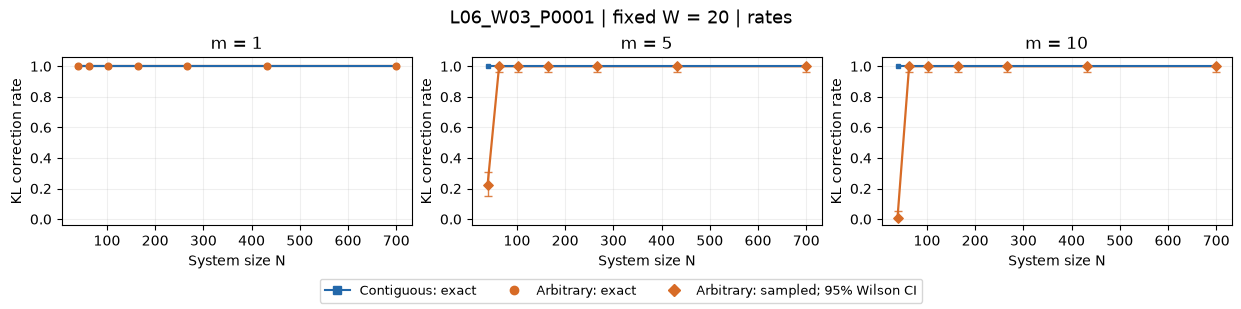

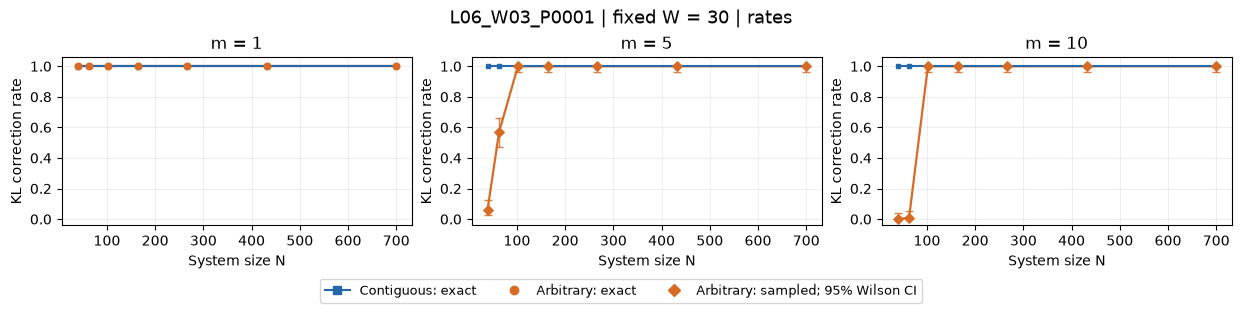

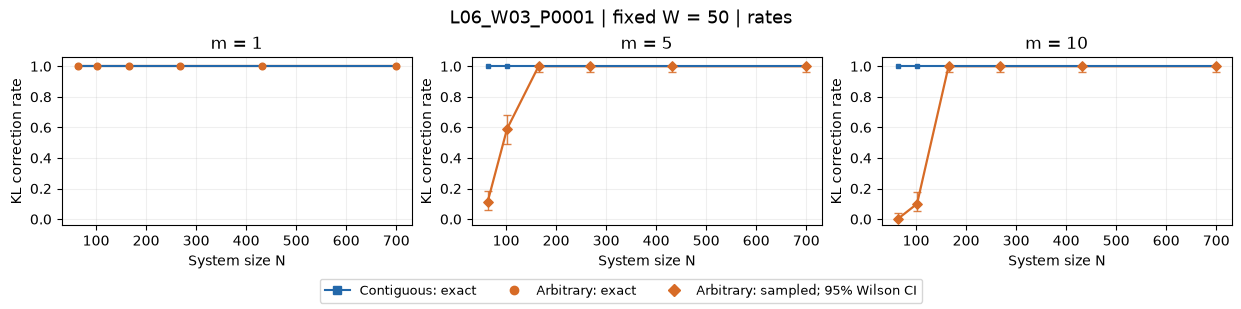

In [16]:
for fig in plot_scaling(summary_df, "rates", Path(OUTPUT_DIR) / "figures", SAVE_FIGURES):
    display(fig)
    plt.close(fig)

## 21. gap / arbitrary failure / 1/N
固定W内の任意消失は連続消失パターンも含みますが、2種類の率は異なる集合の平均なのでgapが負になる可能性もあります。
グラフは負のgapを隠しません。failure rateの0は対数軸ではなく線形軸に表示します。
1/N図にfitは加えません。

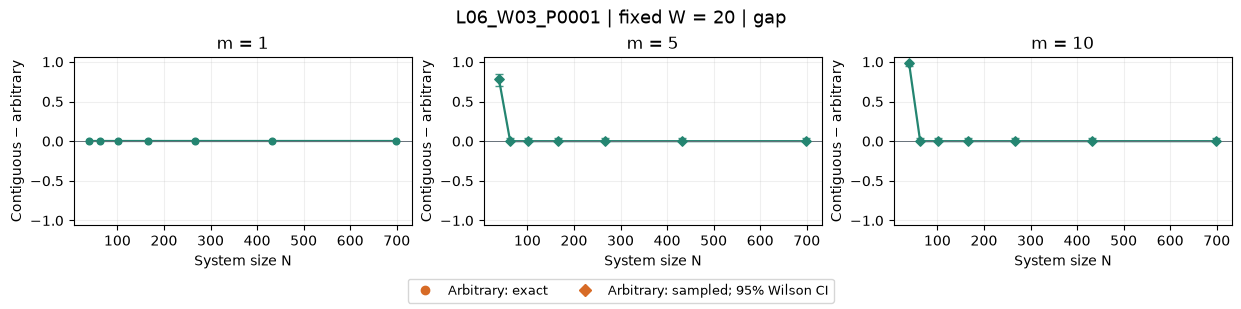

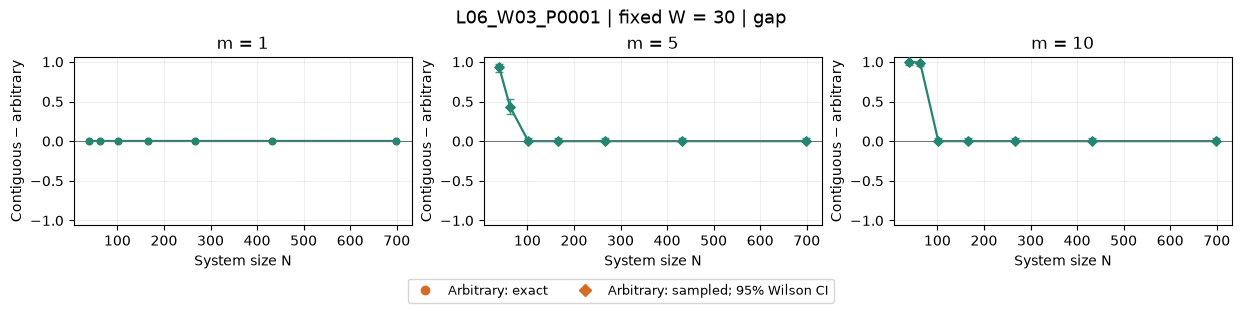

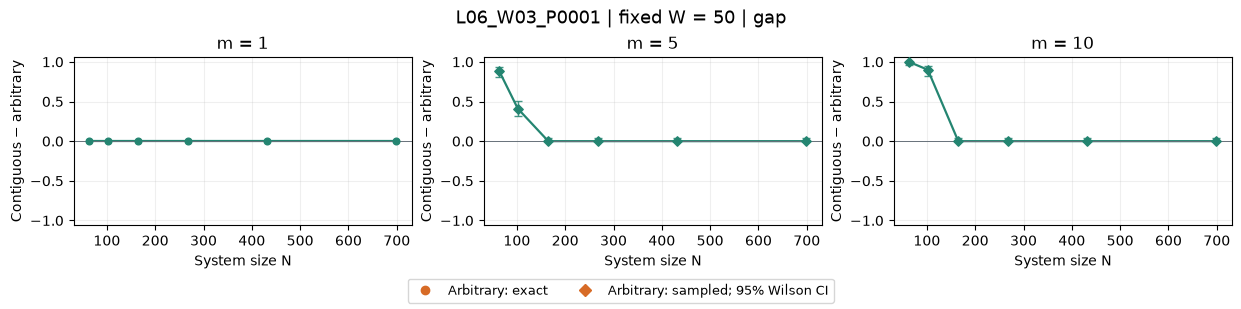

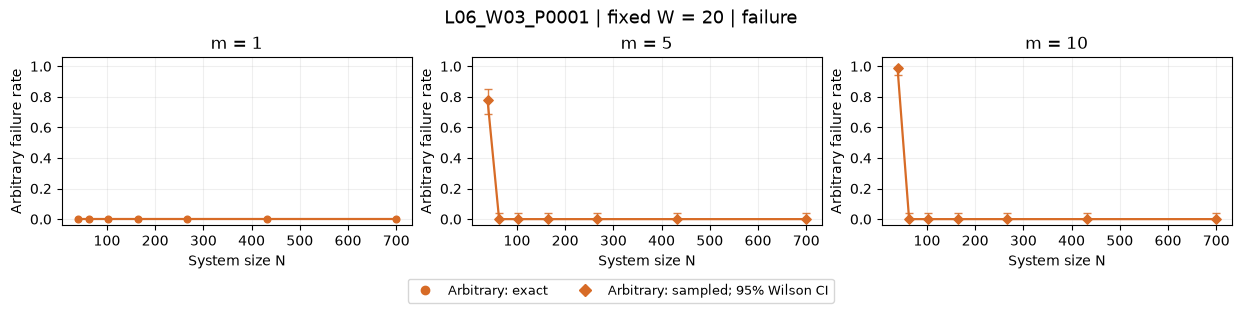

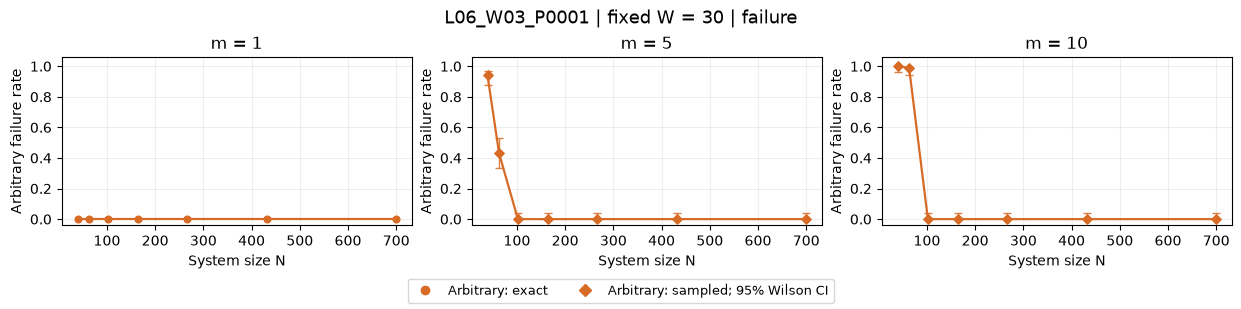

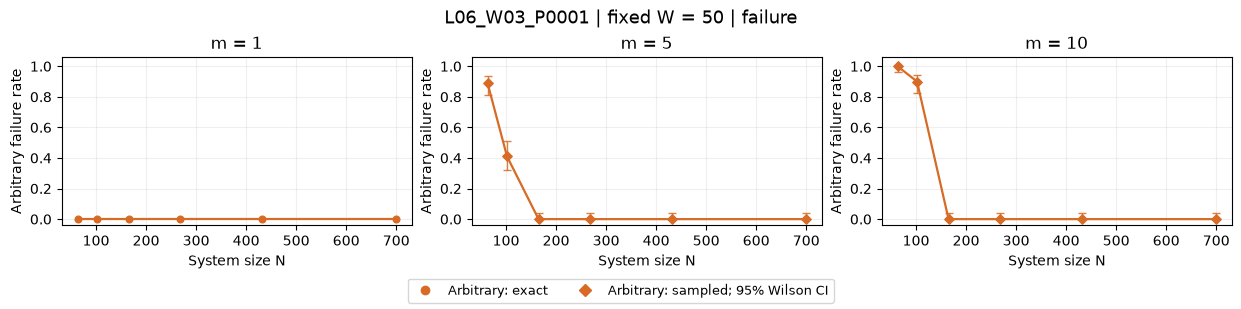

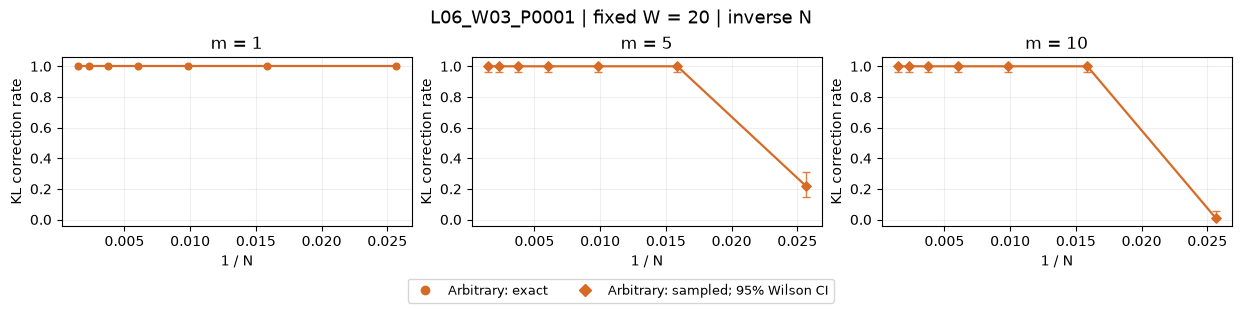

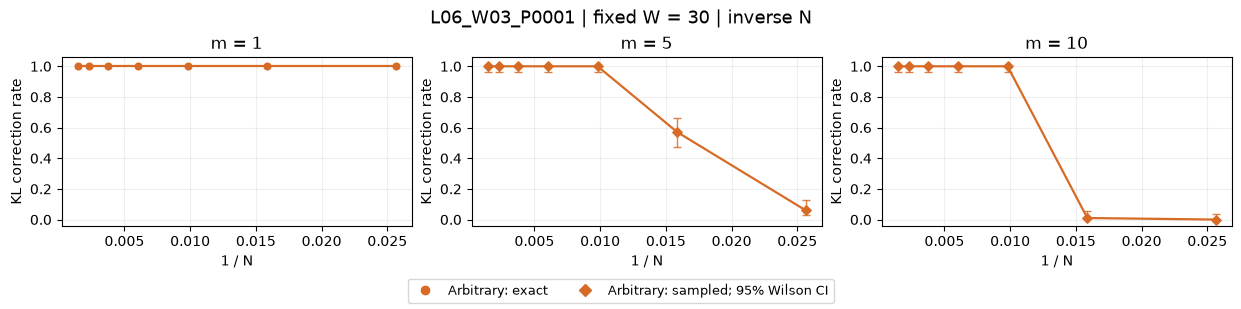

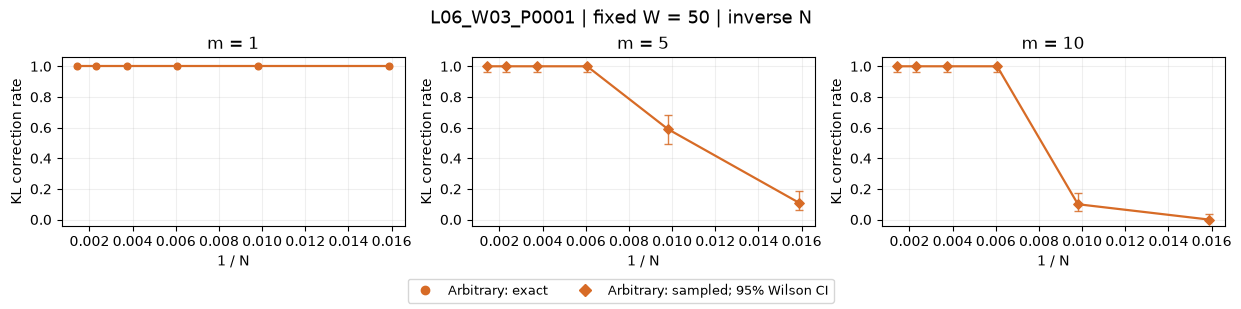

In [17]:
for kind in ["gap", "failure", "inverse_N"]:
    for fig in plot_scaling(summary_df, kind, Path(OUTPUT_DIR) / "figures", SAVE_FIGURES):
        display(fig)
        plt.close(fig)

## 22. heatmap
pair,Wごとに、横軸m、縦軸N、色をKL訂正率とした2種類のheatmapを表示します。
`*` はsampledです。スキップした組は補間せず欠損のまま扱います。

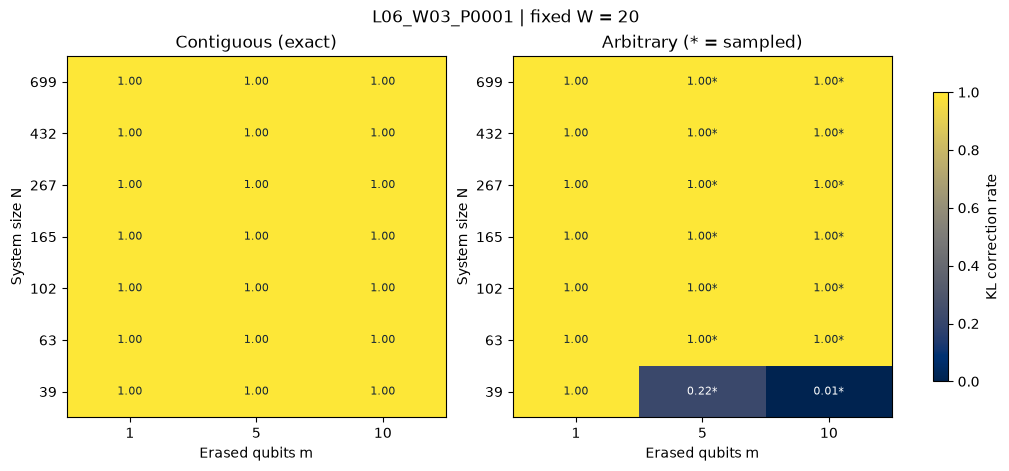

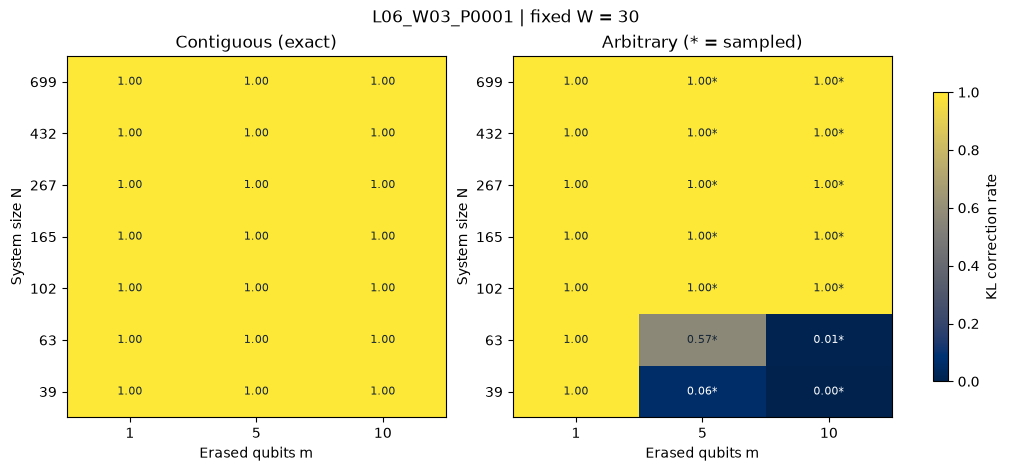

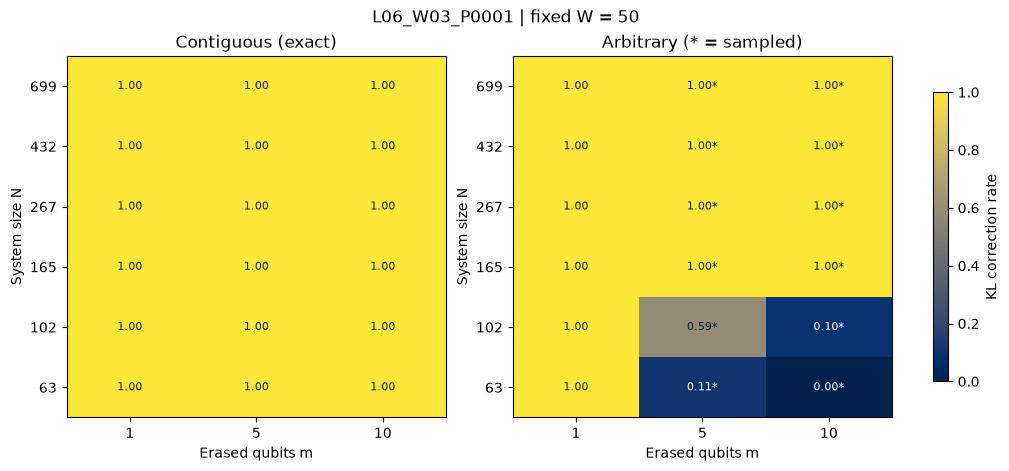

In [18]:
for fig in plot_heatmaps(summary_df, Path(OUTPUT_DIR) / "figures", SAVE_FIGURES):
    display(fig)
    plt.close(fig)

## 23. theoretical scaleとの比較
Li & Boyle, *The Penrose Tiling is a Quantum Error-Correcting Code*, arXiv:2311.13040v2,
[Appendix E.1 / E.3](https://arxiv.org/html/2311.13040v2#A5.SS1) を参照します。
原論文の添字は \(f_0=f_1=1\)、保証長は \(L_{\mathrm{theory}}(n)=f_n+1\) です。
式の値と保証の適用を区別し、n=0や原論文のseed条件を満たさない場合は保証と表示しません。

保証外は「訂正不能」ではなく「この十分条件では未判定」です。詳細は `THEORY.md` を参照してください。
理論上保証されたwindowが数値判定で失敗した場合は停止します。

In [19]:
theory_df = theory_table(prepared)
if result is not None:
    join_keys = ["pair_id", "inflation_n", "N", "window_size"]
    actual = result["windows"]
    keep = join_keys + [c for c in actual.columns if c not in theory_df.columns]
    theory_comparison_df = theory_df.merge(actual[keep], on=join_keys, how="left", validate="one_to_one")
    if "KL_correctable_window" in theory_comparison_df:
        contradiction = theory_comparison_df.theory_window_guaranteed & ~theory_comparison_df.KL_correctable_window.fillna(False).astype(bool)
        if contradiction.any():
            display(theory_comparison_df[contradiction])
            raise AssertionError("理論保証とKL実測値が不一致です。添字・seed条件・orbit・indexを確認してください。")
else:
    theory_comparison_df = theory_df
display(theory_comparison_df)

,pair_id,seed_0,seed_1,inflation_n,N,window_size,window_start,window_end,window_positions_absolute,n,W,L_theory,W_le_L_theory,same_composition,cyclic_inequivalent,cross_swap_01,cross_swap_10,self_swap_0,self_swap_1,adjacent_swap_valid,paper_seed_condition,theory_guarantee_applicable,predicted_window_correctable,theory_window_guaranteed,theory_reference,KL_correctable_window,recoverable_window,KL_diagonal_window,KL_offdiagonal_window
0,L06_W03_P0001,000111,010101,4,39,20,9,28,"(9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20...",4,20,6,False,True,True,False,False,False,False,True,True,True,<NA>,False,"Li & Boyle, arXiv:2311.13040v2, Appendix E.1, ...",False,False,False,False
1,L06_W03_P0001,000111,010101,4,39,30,4,33,"(4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16,...",4,30,6,False,True,True,False,False,False,False,True,True,True,<NA>,False,"Li & Boyle, arXiv:2311.13040v2, Appendix E.1, ...",False,False,False,False
2,L06_W03_P0001,000111,010101,5,63,20,21,40,"(21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 3...",5,20,9,False,True,True,False,False,False,False,True,True,True,<NA>,False,"Li & Boyle, arXiv:2311.13040v2, Appendix E.1, ...",False,False,False,True
3,L06_W03_P0001,000111,010101,5,63,30,16,45,"(16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 2...",5,30,9,False,True,True,False,False,False,False,True,True,True,<NA>,False,"Li & Boyle, arXiv:2311.13040v2, Appendix E.1, ...",False,False,False,False
4,L06_W03_P0001,000111,010101,5,63,50,6,55,"(6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 1...",5,50,9,False,True,True,False,False,False,False,True,True,True,<NA>,False,"Li & Boyle, arXiv:2311.13040v2, Appendix E.1, ...",False,False,False,False
5,L06_W03_P0001,000111,010101,6,102,20,41,60,"(41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 5...",6,20,14,False,True,True,False,False,False,False,True,True,True,<NA>,False,"Li & Boyle, arXiv:2311.13040v2, Appendix E.1, ...",True,True,True,True
6,L06_W03_P0001,000111,010101,6,102,30,36,65,"(36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 4...",6,30,14,False,True,True,False,False,False,False,True,True,True,<NA>,False,"Li & Boyle, arXiv:2311.13040v2, Appendix E.1, ...",False,False,False,True
7,L06_W03_P0001,000111,010101,6,102,50,26,75,"(26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 3...",6,50,14,False,True,True,False,False,False,False,True,True,True,<NA>,False,"Li & Boyle, arXiv:2311.13040v2, Appendix E.1, ...",False,False,False,False
8,L06_W03_P0001,000111,010101,7,165,20,72,91,"(72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 8...",7,20,22,True,True,True,False,False,False,False,True,True,True,True,True,"Li & Boyle, arXiv:2311.13040v2, Appendix E.1, ...",True,True,True,True
9,L06_W03_P0001,000111,010101,7,165,30,67,96,"(67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 7...",7,30,22,False,True,True,False,False,False,False,True,True,True,<NA>,False,"Li & Boyle, arXiv:2311.13040v2, Appendix E.1, ...",True,True,True,True


## 24. threshold解析とlogical pair間比較
`n_star`, `N_star` は**調べたサイズ列の中で**初めて成功率1となったサイズです。未計算サイズも含む真の最小値ではありません。
`sampled_observed` は抽出試行の全成功で、全集合の証明ではありません。exact全成功、全windowのKL成功による保証を区別します。
後続サイズの成功も確認し、最初の率1だけで全てのより大きいNを断定しません。

pair間のmean/median/min/maxは補助表です。seedごとの結果を必ず残し、異なるW,mや異なるNを混ぜません。

In [20]:
if result is not None:
    display(result["thresholds"])
    display(result["pair_statistics"])
assessment_df = convergence_assessment(summary_df)
display(assessment_df)

,pair_id,seed_0,seed_1,window_size,erasure_size,threshold_kind,found,n_star,N_star,proven_all_patterns,all_later_tested_sizes_pass,later_tested_size_count,interpretation,ci95_low,ci95_high
0,L06_W03_P0001,000111,010101,20,1,exact_enumeration,True,4.0,39.0,True,True,6,minimum within tested sizes; not an asymptotic...,1.000000,1.0
1,L06_W03_P0001,000111,010101,20,1,full_window_proof,True,6.0,102.0,True,True,4,minimum within tested sizes; not an asymptotic...,1.000000,1.0
2,L06_W03_P0001,000111,010101,20,1,sampled_observed,False,NaN,NaN,False,None,0,minimum within tested sizes; not an asymptotic...,NaN,NaN
3,L06_W03_P0001,000111,010101,20,5,exact_enumeration,False,NaN,NaN,False,None,0,minimum within tested sizes; not an asymptotic...,NaN,NaN
4,L06_W03_P0001,000111,010101,20,5,full_window_proof,True,6.0,102.0,True,True,4,minimum within tested sizes; not an asymptotic...,0.963007,1.0
5,L06_W03_P0001,000111,010101,20,5,sampled_observed,True,5.0,63.0,False,True,5,minimum within tested sizes; not an asymptotic...,0.963007,1.0
6,L06_W03_P0001,000111,010101,20,10,exact_enumeration,False,NaN,NaN,False,None,0,minimum within tested sizes; not an asymptotic...,NaN,NaN
7,L06_W03_P0001,000111,010101,20,10,full_window_proof,True,6.0,102.0,True,True,4,minimum within tested sizes; not an asymptotic...,0.963007,1.0
8,L06_W03_P0001,000111,010101,20,10,sampled_observed,True,5.0,63.0,False,True,5,minimum within tested sizes; not an asymptotic...,0.963007,1.0
9,L06_W03_P0001,000111,010101,30,1,exact_enumeration,True,4.0,39.0,True,True,6,minimum within tested sizes; not an asymptotic...,1.000000,1.0


,inflation_n,N,window_size,erasure_size,R_KL_contiguous_mean,R_KL_contiguous_median,R_KL_contiguous_min,R_KL_contiguous_max,R_KL_contiguous_count,R_KL_arbitrary_mean,R_KL_arbitrary_median,R_KL_arbitrary_min,R_KL_arbitrary_max,R_KL_arbitrary_count,gap_KL_mean,gap_KL_median,gap_KL_min,gap_KL_max,gap_KL_count
0,4,39,20,1,1.0,1.0,1.0,1.0,1,1.00,1.00,1.00,1.00,1,0.00,0.00,0.00,0.00,1
1,4,39,20,5,1.0,1.0,1.0,1.0,1,0.22,0.22,0.22,0.22,1,0.78,0.78,0.78,0.78,1
2,4,39,20,10,1.0,1.0,1.0,1.0,1,0.01,0.01,0.01,0.01,1,0.99,0.99,0.99,0.99,1
3,4,39,30,1,1.0,1.0,1.0,1.0,1,1.00,1.00,1.00,1.00,1,0.00,0.00,0.00,0.00,1
4,4,39,30,5,1.0,1.0,1.0,1.0,1,0.06,0.06,0.06,0.06,1,0.94,0.94,0.94,0.94,1
5,4,39,30,10,1.0,1.0,1.0,1.0,1,0.00,0.00,0.00,0.00,1,1.00,1.00,1.00,1.00,1
6,5,63,20,1,1.0,1.0,1.0,1.0,1,1.00,1.00,1.00,1.00,1,0.00,0.00,0.00,0.00,1
7,5,63,20,5,1.0,1.0,1.0,1.0,1,1.00,1.00,1.00,1.00,1,0.00,0.00,0.00,0.00,1
8,5,63,20,10,1.0,1.0,1.0,1.0,1,1.00,1.00,1.00,1.00,1,0.00,0.00,0.00,0.00,1
9,5,63,30,1,1.0,1.0,1.0,1.0,1,1.00,1.00,1.00,1.00,1,0.00,0.00,0.00,0.00,1


,pair_id,window_size,erasure_size,N_first,N_last,R_first,R_last,observed_change,gap_last,delta_last,observed_nondecreasing,all_sizes_exact,interpretation,observed_Delta_R_nonincreasing
0,L06_W03_P0001,20,1,39,699,1.00,1.0,0.00,0.0,0.0,True,True,観測した全サイズで成功率1。改善前のサイズはこの系列に含まれない。,True
1,L06_W03_P0001,20,5,39,699,0.22,1.0,0.78,0.0,0.0,True,False,観測範囲では任意消失の訂正率が改善。有限サイズ効果と整合的。 sampling値を含むため、...,True
2,L06_W03_P0001,20,10,39,699,0.01,1.0,0.99,0.0,0.0,True,False,観測範囲では任意消失の訂正率が改善。有限サイズ効果と整合的。 sampling値を含むため、...,True
3,L06_W03_P0001,30,1,39,699,1.00,1.0,0.00,0.0,0.0,True,True,観測した全サイズで成功率1。改善前のサイズはこの系列に含まれない。,True
4,L06_W03_P0001,30,5,39,699,0.06,1.0,0.94,0.0,0.0,True,False,観測範囲では任意消失の訂正率が改善。有限サイズ効果と整合的。 sampling値を含むため、...,True
5,L06_W03_P0001,30,10,39,699,0.00,1.0,1.00,0.0,0.0,True,False,観測範囲では任意消失の訂正率が改善。有限サイズ効果と整合的。 sampling値を含むため、...,False
6,L06_W03_P0001,50,1,63,699,1.00,1.0,0.00,0.0,0.0,True,True,観測した全サイズで成功率1。改善前のサイズはこの系列に含まれない。,True
7,L06_W03_P0001,50,5,63,699,0.11,1.0,0.89,0.0,0.0,True,False,観測範囲では任意消失の訂正率が改善。有限サイズ効果と整合的。 sampling値を含むため、...,True
8,L06_W03_P0001,50,10,63,699,0.00,1.0,1.00,0.0,0.0,True,False,観測範囲では任意消失の訂正率が改善。有限サイズ効果と整合的。 sampling値を含むため、...,False


## 25. 結果まとめ
数値的な改善はfinite-size effectと整合的ですが、固定Wの結果から従来のring全域の任意消失まで一般化しません。
改善が観測されない場合も、試したサイズ範囲とsampling精度を確認し、より大きいNでの可能性を即座には否定しません。

原論文の条件を満たすpairでは、固定Wが理論保証長に入った後の全subset訂正は理論からも従います。
その前の変化、実測threshold、保証との整合性を本Notebookで調べます。
mutual information、correlation、structure factor、seed最適化、Hamiltonian、2D modelは今回の範囲に含めません。

In [21]:
display(Markdown(conclusion_markdown(prepared, config, result, theory_comparison_df)))
display(size_df)
if not summary_df.empty:
    display(summary_df[["pair_id", "inflation_n", "N", "window_size", "erasure_size",
                        "R_KL_contiguous", "R_KL_arbitrary", "gap_KL", "calculation_mode"]])
if SAVE_RESULTS:
    destination = Path(OUTPUT_DIR)
    destination.mkdir(parents=True, exist_ok=True)
    for name, table in {"size_table": size_df, "seed_checks": seed_checks_df,
                        "pattern_plan": pattern_plan_df, "translation_test": translation_df,
                        "benchmark": benchmark_df, "small_validation": validation_df,
                        "theory_comparison": theory_comparison_df, "convergence_assessment": assessment_df}.items():
        table.to_csv(destination / (name + ".csv"), index=False)
    (destination / "notebook_config.json").write_text(json.dumps(config, ensure_ascii=False, indent=2))
    (destination / "conclusions.md").write_text(conclusion_markdown(prepared, config, result, theory_comparison_df))

### 自動まとめ

- `L06_W03_P0001`: seed 0 = `000111` / seed 1 = `010101`。指定の隣接交換条件: 合格。
- INFLATION_LIST = `[4, 5, 6, 7, 8, 9, 10]`
- WINDOW_SIZE_LIST = `[20, 30, 50]`
- ERASURE_SIZE_LIST = `[1, 5, 10]`

有効な集計行数: 60。各Nの訂正率とgap、thresholdは上の表を参照してください。
任意消失の観測率1: 50 / 60 組。exactとsampledを区別して解釈します。
window全体のKL成功: 12 / 20 組。成功したwindow内では未抽出の部分集合を含め訂正可能です。
原論文の条件と保証長を満たすwindow: 9 / 20 組。条件内では固定W全体とその全ての部分集合の訂正が保証されます。

固定Wの結果は、ring全域から消失位置を選ぶ従来の実験とは異なる問いに答えます。単一Nを無限系と呼ばず、無根拠な1/N fitは行いません。
samplingの95%区間は各点のWilson区間です。同じ試行をサイズ間で共有するため各Nの推定値は相関し、区間の重なりだけで変化の有意性を判定できません。

,pair_id,seed_length,k0,k1,adjacent_swap_valid,seed_0,seed_1,inflation_n,N,orbit_size_0,orbit_size_1
0,L06_W03_P0001,6,3,3,True,000111,010101,4,39,39,13
1,L06_W03_P0001,6,3,3,True,000111,010101,5,63,63,21
2,L06_W03_P0001,6,3,3,True,000111,010101,6,102,102,34
3,L06_W03_P0001,6,3,3,True,000111,010101,7,165,165,55
4,L06_W03_P0001,6,3,3,True,000111,010101,8,267,267,89
5,L06_W03_P0001,6,3,3,True,000111,010101,9,432,432,144
6,L06_W03_P0001,6,3,3,True,000111,010101,10,699,699,233


,pair_id,inflation_n,N,window_size,erasure_size,R_KL_contiguous,R_KL_arbitrary,gap_KL,calculation_mode
0,L06_W03_P0001,4,39,20,1,1.0,1.00,0.00,exact
1,L06_W03_P0001,5,63,20,1,1.0,1.00,0.00,exact
2,L06_W03_P0001,6,102,20,1,1.0,1.00,0.00,exact
3,L06_W03_P0001,7,165,20,1,1.0,1.00,0.00,exact
4,L06_W03_P0001,8,267,20,1,1.0,1.00,0.00,exact
5,L06_W03_P0001,9,432,20,1,1.0,1.00,0.00,exact
6,L06_W03_P0001,10,699,20,1,1.0,1.00,0.00,exact
7,L06_W03_P0001,4,39,20,5,1.0,0.22,0.78,sampled
8,L06_W03_P0001,5,63,20,5,1.0,1.00,0.00,sampled
9,L06_W03_P0001,6,102,20,5,1.0,1.00,0.00,sampled
